In [493]:
#Imports
import kagglehub
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, ShuffleSplit

from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mne.set_log_level("WARNING")

### Load, filter, and separate into epochs

The three CSV files are concentrated into an EEG array $X_k \in \mathbb{R}^{8 \times T}$, where $T$ is the number of time samples in the three files. 

Data was filtered for $f \in (7, 30)\,\text{Hz}$ and Epochs were filtered for $t \in (0.5, 4.5)\, \text{s}$ to account for reaction delay.

<Epochs | 110 events (all good), 0.5 – 4.5 s (baseline off), ~6.7 MiB, data loaded,
 'rest': 55
 'move': 55>


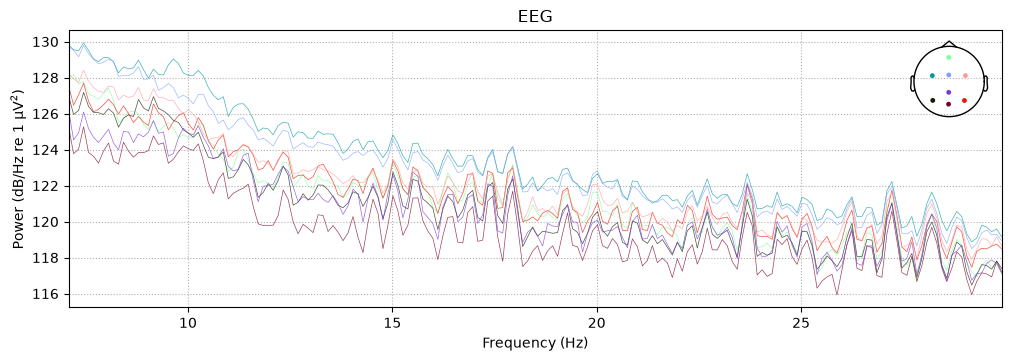

In [503]:
#Load Data
PATHS = ["Data/Training Set/S001-001_eeg.csv","Data/Training Set/S001-002_eeg.csv","Data/Training Set/S001-003_eeg.csv"]

#Declare Constants
SFREQ = 250 #Frequency of the eeg
ch_names = ['C4', 'C3', 'Cz','Fz','PO7','Pz','PO8','Oz'] #Channels used in the eeg

#Converting csv to rawArray for mne
df = pd.concat([pd.read_csv(path) for path in PATHS],ignore_index=True)

#Data
eegdata = np.concatenate([pd.read_csv(path)[ch_names].to_numpy().T for path in PATHS],axis=1)

#Information
info = mne.create_info(ch_names=ch_names,sfreq=SFREQ,ch_types="eeg")

#Converting marker to annotation
markers =df["Marker_val"]
cue_indices = df.index[markers.isin(['move', 'rest'])].tolist() #Get index of when move and rest is happening
onset = []
duration = []
description = []
for label_idx in cue_indices:
    label_str = markers.loc[label_idx]
    start_second = label_idx/SFREQ
    onset.append(start_second)
    description.append(label_str)
anno = mne.Annotations(onset=onset,duration=0,description=description) 

raw = mne.io.RawArray(eegdata,info)
raw.set_annotations(anno)
raw.set_montage("colin27_1005")
raw.filter(l_freq=7.,h_freq=30.)
epochs = mne.Epochs(
    raw,
    event_id=["move","rest"],
    tmin = 0.5,
    tmax = 4.5,
    proj=True,
    baseline=None,
    preload=True,
)
print(epochs)          
epochs.get_data().shape
epochs_train = epochs.copy()
label = epochs.events[:,2]
raw.compute_psd(fmin=7,fmax=30).plot();

### ML Pipeline with CSP and LDA
Common Spatial Pattern (CSP) and Linear Discriminant Analysis (LDA) was used in a Cross Validation testing, returning scores around $64 - 72$

In [ ]:
epochs_data = epochs.get_data(copy = False)
epochs_data_train = epochs_train.get_data(copy = False)
cv = ShuffleSplit(test_size=0.2)
lda = LDA()
csp = CSP(n_components=4, reg=None, log=True, norm_trace=False)
clf = Pipeline([("CSP",csp),("LDA",lda)])
scores = cross_val_score(clf, epochs_data_train, label, cv=cv)
print(f"Classification accuracy: {np.mean(scores)}")

Classification accuracy: 0.618181818181818 / Chance level: 0.5


<Epochs | 40 events (all good), 0.5 – 4.5 s (baseline off), ~2.5 MiB, data loaded,
 'cue_start': 40>


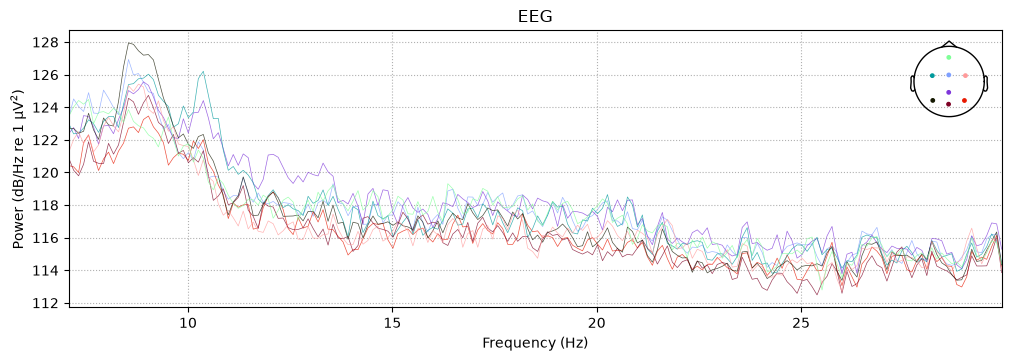

In [504]:
#Load Data
PATH = "Data/Single subject test set/S001_test.csv"

#Converting csv to rawArray for mne
df = pd.read_csv(PATH)

#Data
eegdata = pd.read_csv(PATH)[ch_names].to_numpy().T

#Information
info = mne.create_info(ch_names=ch_names,sfreq=SFREQ,ch_types="eeg")

#Converting marker to annotation
markers =df["Marker_val"]
cue_indices = df.index[markers.isin(["cue_start"])].tolist() #Get index of when move and rest is happening
onset = []
duration = []
description = []
for label_idx in cue_indices:
    label_str = markers.loc[label_idx]
    start_second = label_idx/SFREQ
    onset.append(start_second)
    description.append(label_str)
anno = mne.Annotations(onset=onset,duration=0,description=description) 

raw = mne.io.RawArray(eegdata,info)
raw.set_annotations(anno)
raw.set_montage("colin27_1005")
raw.filter(l_freq=7.,h_freq=30.)
epochs = mne.Epochs(
    raw,
    event_id=["cue_start"],
    tmin = 0.5,
    tmax = 4.5,
    proj=True,
    baseline=None,
    preload=True,
)
print(epochs)          
epochs.get_data().shape
epochs_test = epochs.copy()
raw.compute_psd(fmin=7,fmax=30).plot();

In [505]:
clf.fit(epochs_data_train, label)
results = clf.predict(epochs_test.get_data(copy = False))
binah = ["move","rest"]
dataframe = []
for i in range(len(results)):
    dataframe.append({"ID":i, "TARGET": binah[results[i]-1]})
result = pd.DataFrame(dataframe)
result.to_csv("results.csv", index=False)

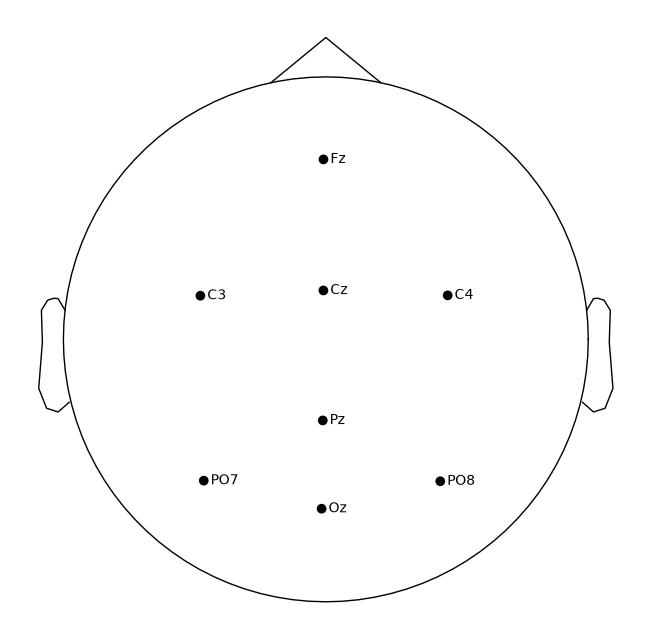

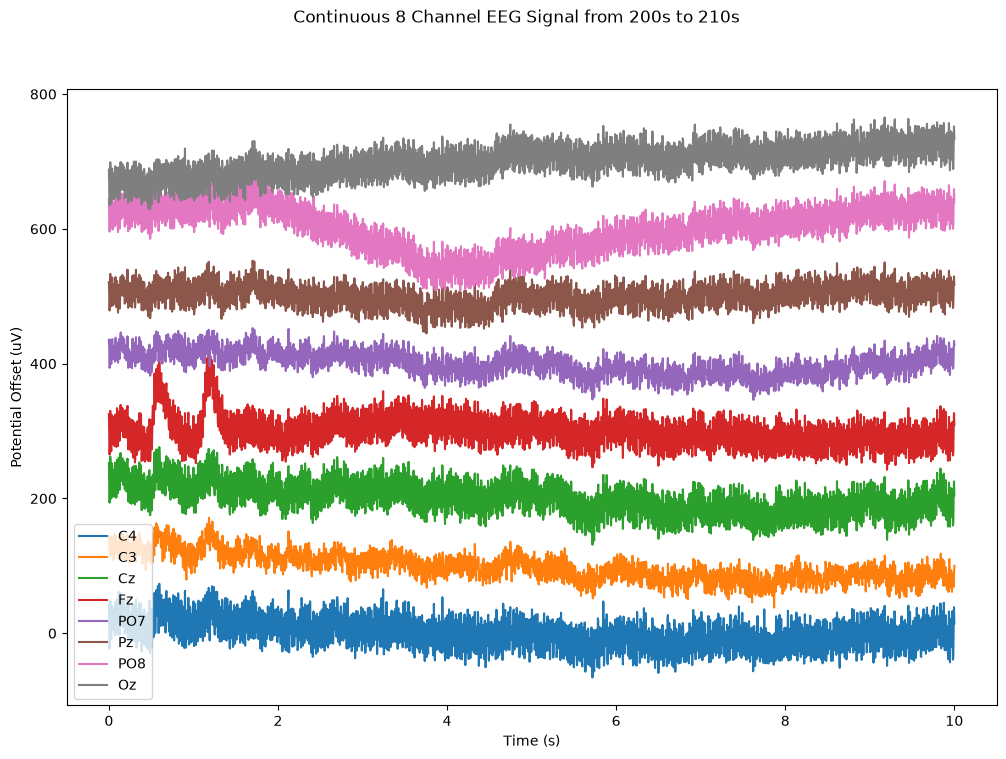

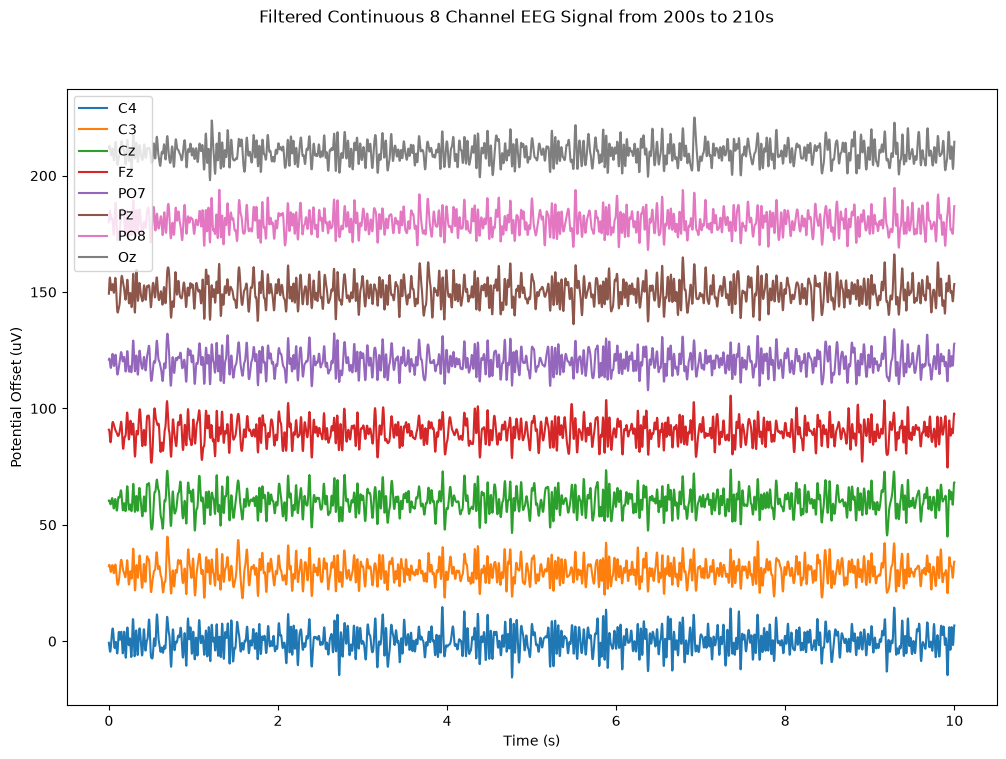

In [496]:
#Sensor Plot
raw.plot_sensors(show_names=True)
sample = df.loc[50000:52500, ch_names]

#Unfiltered EEG Signal Plot
plt.figure(figsize=(12, 8))
for i in range(len(ch_names)):
    plt.plot(np.array(range(len(sample[ch_names[1]])))/250,sample[ch_names[i]]-np.mean(sample[ch_names[i]])+100*i,label=ch_names[i])
plt.xlabel("Time (s)")
plt.ylabel("Potential Offset (uV)")
plt.suptitle("Continuous 8 Channel EEG Signal from 200s to 210s")
plt.legend()
plt.show()

#Filtered EEG Signal Plot
filtered_sample = raw.copy().crop(tmin=200,tmax=210).get_data()
plt.figure(figsize=(12, 8))
for i in range(len(ch_names)):
    plt.plot(np.array(range(len(filtered_sample[i])))/250,filtered_sample[i]-np.mean(filtered_sample[i])+30*i,label=ch_names[i])
plt.xlabel("Time (s)")
plt.ylabel("Potential Offset (uV)")
plt.suptitle("Filtered Continuous 8 Channel EEG Signal from 200s to 210s")
plt.legend()
plt.show()